In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import tensorflow as tf 

/usr/lib/python3/dist-packages/pyparsing/core.py:5332: SyntaxWarning: 'return' in a 'finally' block
  return self.__class__.__name__ + ": " + retString
I0000 00:00:1793469134.191429  466323 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793469134.312305  466323 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793469138.657220  466323 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
(x_train, y_train),(x_test, y_test) = keras.datasets.cifar10.load_data()

In [3]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)


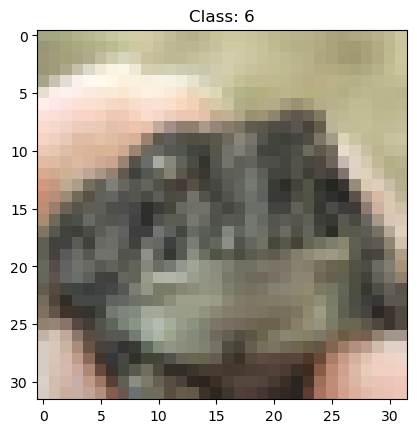

In [4]:
plt.imshow(x_train[25])
plt.title("Class: " + str(y_train[25][0]))
plt.show()

In [5]:
## normalzing
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0


In [6]:
print("Training data:", x_train.shape, x_train.dtype)
print("Testing data:", x_test.shape, x_test.dtype)

print("Training memory:",
      x_train.nbytes / (1024 ** 2), "MB")

print("Testing memory:",
      x_test.nbytes / (1024 ** 2), "MB")

Training data: (50000, 32, 32, 3) float32
Testing data: (10000, 32, 32, 3) float32
Training memory: 585.9375 MB
Testing memory: 117.1875 MB


In [7]:

## define class names

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

num_classes = 10

y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print("encoding one hot labels done!")

## model creation

model = keras.Sequential()

model.add(keras.layers.Conv2D(
    32, (3,3),
    activation="relu",
    input_shape=(32,32,3)
))

model.add(
    keras.layers.MaxPooling2D((2,2))
)

model.add(
    keras.layers.Conv2D(
        64,(3,3),
        activation="relu"
    )
)

model.add(
    keras.layers.MaxPooling2D((2,2))
)

model.add(
    keras.layers.Conv2D(
        64,(3,3),
        activation="relu"
    )
)

model.add(
    keras.layers.Flatten()
)

model.add(
    keras.layers.Dense(
        64,
        activation="relu"
    )
)

model.add(
    keras.layers.Dense(
        10,
        activation="softmax"
    )
)

model.summary()

encoding one hot labels done!


/usr/local/lib/python3.14/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1793469160.280443  466323 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
## compile the model

model.compile(
    optimizer="sgd",
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("model compiled!")

model compiled!


In [9]:
## training model

hist = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=10,
    validation_data=(x_test, y_test),
    shuffle=True
)

Epoch 1/10


W0000 00:00:1793469168.353564  466323 cpu_allocator_impl.cc:174] Allocation of 614400000 exceeds 10% of free system memory.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.2478 - loss: 2.0479

W0000 00:00:1793469210.577012  466323 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 44s 28ms/step - accuracy: 0.2478 - loss: 2.0479 - val_accuracy: 0.3215 - val_loss: 1.9790
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 79s 26ms/step - accuracy: 0.4101 - loss: 1.6356 - val_accuracy: 0.4229 - val_loss: 1.6484
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 26ms/step - accuracy: 0.4756 - loss: 1.4549 - val_accuracy: 0.4745 - val_loss: 1.4941
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 43s 27ms/step - accuracy: 0.5189 - loss: 1.3445 - val_accuracy: 0.5138 - val_loss: 1.3760
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 26ms/step - accuracy: 0.5512 - loss: 1.2597 - val_accuracy: 0.5420 - val_loss: 1.3063
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 45s 29ms/step - accuracy: 0.5807 - loss: 1.1869 - val_accuracy: 0.5607 - val_loss: 1.2680
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 79s 27ms/step - accuracy: 0.6045 - loss: 1.1226 - val_accuracy: 0.5788 - val_loss: 1.2155
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 43s 27ms/step - accuracy: 0.6243 - loss: 1.06

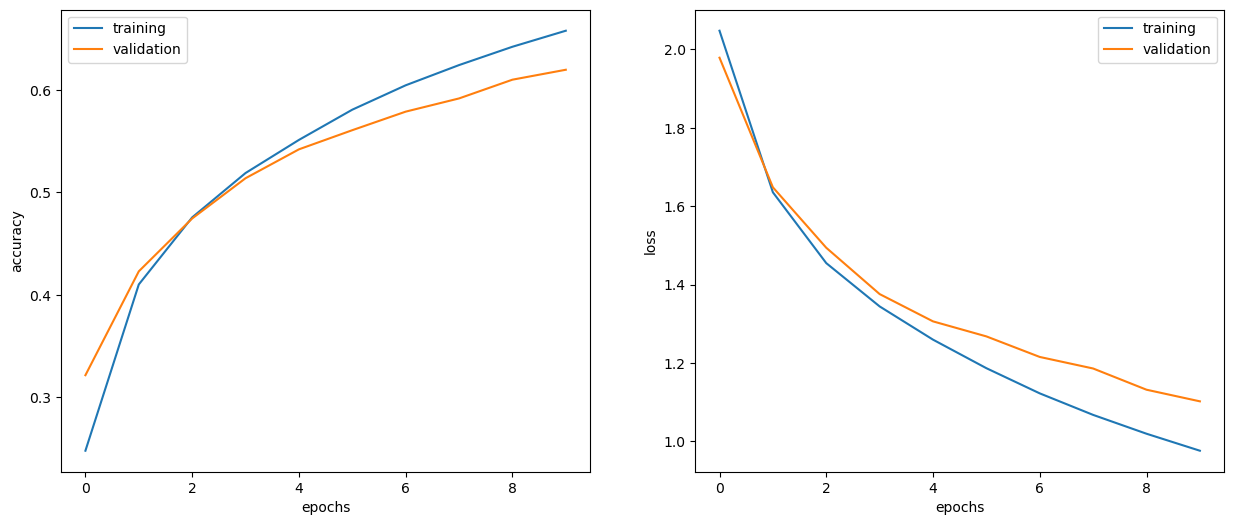

In [12]:
## plot graphs for the accuracy and loss

plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
plt.plot(hist.history['accuracy'])
plt.plot(hist.history["val_accuracy"])
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.legend(['training', 'validation'])


plt.subplot(1,2,2)
plt.plot(hist.history['loss'])
plt.plot(hist.history["val_loss"])
plt.xlabel("epochs")
plt.ylabel("loss")
plt.legend(['training', 'validation'])

plt.show()

In [13]:
## evaluate

loss, accuracy = model.evaluate(x_test, y_test)
print(loss, accuracy, accuracy*100)

  8/313 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6289 - loss: 1.0653

W0000 00:00:1793470192.113206  466323 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6197 - loss: 1.1023
1.1022913455963135 0.619700014591217 61.970001459121704


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


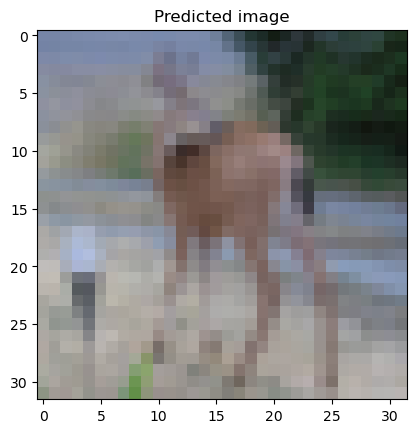

Predicted Value: 4
Actual image: [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


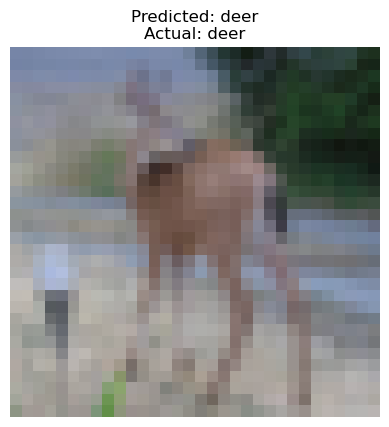

In [19]:
predicted_value = model.predict(x_test, batch_size=32)

index = 100

plt.imshow(x_test[index], cmap='gray')
plt.title("Predicted image")
plt.show()

print("Predicted Value:",
      np.argmax(predicted_value[index]))

print("Actual image:",
      y_test[index])


predicted_class = np.argmax(predicted_value[index])
actual_class = np.argmax(y_test[index])

plt.imshow(x_test[index])
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis('off')
plt.show()